# 1st round - Step 2: cleaning

Rules: **fix only what is provably wrong** (the data themselves show the error), **log every
change** (`reports/02_cleaning/cleaning_log.csv`) and flag every changed row (`dq_` columns),
**never drop** policy, customer, address or weather rows (only exact duplicate claims are removed),
and **do not impute** missing values (step 3 decides how each one is handled).

The script `python 02_data_cleaning.py` writes `data/clean/` (same file names as the case study).
This notebook applies the same functions rule by rule and shows each rule's effect.

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")

cleaning = importlib.import_module("02_data_cleaning")
raw = {n: H.read_table(n, "raw") for n in C.TABLES}
log = H.ChangeLog("notebook")

1st round - developed market - IAA AI-Assisted Hackathon 2026 - Part 1


## 1. Identifiers: lost leading zeros

In [2]:
def lengths(s):
    return {int(k): int(v) for k, v in s.str.len().value_counts().sort_index().items()}

for t in C.POLICY_TABLES:
    before = lengths(raw[t]["customer_id"])
    after = lengths(cleaning.pad_ids(raw[t], t, log)["customer_id"])
    print(f"{t:<20} customer_id lengths before {before} -> after {after}")

  [C03] policies_motor.customer_id: lost leading zeros restored (width 8) -> 98,110 rows (zero-padded)
policies_motor       customer_id lengths before {2: 5, 3: 11, 4: 79, 5: 927, 6: 8958, 7: 88130, 8: 881858} -> after {8: 979968}
policies_buildings   customer_id lengths before {8: 707726} -> after {8: 707726}
policies_contents    customer_id lengths before {8: 721617} -> after {8: 721617}


  [C03] test_motor.customer_id: lost leading zeros restored (width 8) -> 25,554 rows (zero-padded)
test_motor           customer_id lengths before {2: 1, 3: 3, 4: 18, 5: 241, 6: 2316, 7: 22975, 8: 229432} -> after {8: 254986}
test_buildings       customer_id lengths before {8: 184155} -> after {8: 184155}
test_contents        customer_id lengths before {8: 187498} -> after {8: 187498}


## 2. Exposure recomputed from the dates

In [3]:
fixed = {t: cleaning.fix_exposure(raw[t], t, log) for t in C.POLICY_TABLES}
t = "policies_motor"
d = fixed[t]
bad = d["dq_exposure_fixed"] == 1
pd.DataFrame({"exposure as recorded": raw[t].loc[bad, "exposure"].head(8).to_numpy(),
              "days on cover": ((d["period_end"] - d["period_start"]).dt.days + 1)[bad].head(8).to_numpy(),
              "exposure fixed": d.loc[bad, "exposure"].head(8).round(4).to_numpy()})

  [C04] policies_motor.exposure: exposure recomputed from the period dates (days / 365) -> 5,596 rows (recomputed)


  [C04] policies_buildings.exposure: exposure recomputed from the period dates (days / 365) -> 4,078 rows (recomputed)


  [C04] policies_contents.exposure: exposure recomputed from the period dates (days / 365) -> 4,206 rows (recomputed)


,exposure as recorded,days on cover,exposure fixed
0,1.0139,365,1.0000
1,1.0139,365,1.0000
2,327.0000,327,0.8959
3,1.0139,365,1.0000
4,0.4778,172,0.4712
5,1.0139,365,1.0000
6,1.0139,365,1.0000
7,1.0139,365,1.0000


## 3. Sums insured recorded in units instead of thousands

  [C05] policies_buildings.sum_insured: sum insured > 100x the median (223,000) divided by 1,000 -> 1,395 rows (rescaled)


  [C05] policies_contents.sum_insured: sum insured > 100x the median (39,000) divided by 1,000 -> 1,402 rows (rescaled)


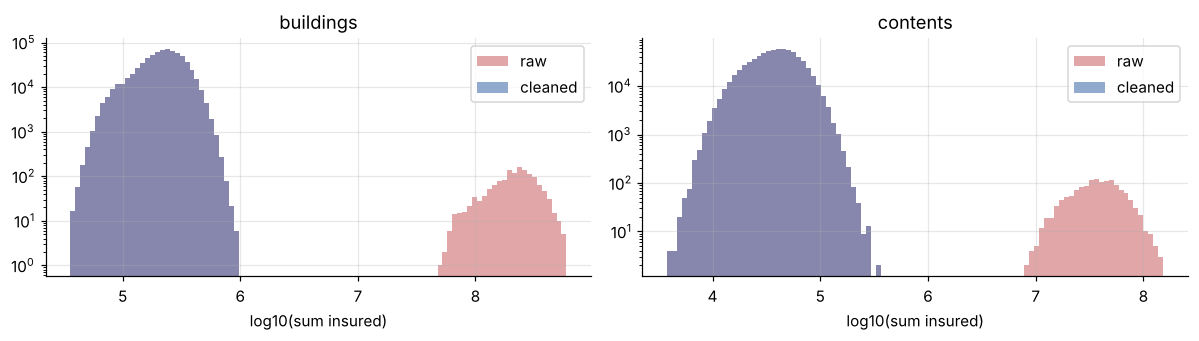

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, line in zip(axes, ["buildings", "contents"]):
    t = f"policies_{line}"
    after = cleaning.fix_sum_insured(raw[t], t, log)
    bins = np.histogram_bin_edges(np.log10(raw[t]["sum_insured"].dropna()), bins=100)  # same bins for both
    ax.hist(np.log10(raw[t]["sum_insured"]), bins=bins, alpha=0.5, label="raw", color="#C44E52")
    ax.hist(np.log10(after["sum_insured"]), bins=bins, alpha=0.6, label="cleaned", color="#4C72B0")
    ax.set_yscale("log"); ax.set_xlabel("log10(sum insured)"); ax.set_title(line); ax.legend()
plt.tight_layout(); plt.show()

## 4. One spelling per category

In [5]:
cust = cleaning.normalise_codes(raw["customers"], "customers", log)
cust = cleaning.split_self_employed(cust, "customers", log)
b = cleaning.normalise_codes(raw["policies_buildings"], "policies_buildings", log)
pd.DataFrame({"raw": raw["policies_buildings"]["construction_type"].value_counts(),
              "cleaned": b["construction_type"].value_counts()}).fillna(0).astype(int)

  [C01] customers.occupation: one spelling per category (trim, case, local codes) -> 531,778 rows (recoded)


  [C01] policies_buildings.construction_type: one spelling per category (trim, case, local codes) -> 560,124 rows (recoded)


,raw,cleaned
construction_type,,
BRICK,14709,0
Brick,456072,0
NON_STANDARD,2097,0
STONE,1690,0
T,38937,0
W,42319,0
brick,24863,495644
non_standard,68036,70133
stone,54703,56393


In [6]:
print("occupations:", cust["occupation"].nunique(), "levels after cleaning (raw:", raw["customers"]["occupation"].nunique(), ")")
if "self_employed" in cust:
    print("self-employed customers:", int(cust["self_employed"].sum()))

occupations: 20 levels after cleaning (raw: 20 )


## 5. Driver history: impossible years licensed (1st round)
A driver's age at first licence is the same in every row of a policy. Rows where it falls below 17 take it from the policy's other rows; a policy without another row is capped at age - 17.

In [7]:
tabs = {t: cleaning.pad_ids(raw[t], t, log) for t in ("policies_motor", "test_motor")}
if "driver_age" in tabs["policies_motor"]:
    rep = cleaning.repair_years_licensed(dict(tabs), log)
    m0, m1 = tabs["policies_motor"], rep["policies_motor"]
    ex = m1.loc[m1["dq_years_licensed_fixed"] == 1, "policy_id"].iloc[0]
    view = m0.loc[m0["policy_id"] == ex, ["policy_id", "period_start", "driver_age", "years_licensed"]].copy()
    view["years_licensed cleaned"] = m1.loc[m1["policy_id"] == ex, "years_licensed"].to_numpy()
    view["age at first licence (raw)"] = view["driver_age"] - view["years_licensed"]
    display(view)
else:
    print("2nd round: age bands only, the check is not possible")

  [C03] policies_motor.customer_id: lost leading zeros restored (width 8) -> 98,110 rows (zero-padded)
  [C03] test_motor.customer_id: lost leading zeros restored (width 8) -> 25,554 rows (zero-padded)


  [C07] policies_motor.years_licensed: licence before age 17 is impossible -> 2,962 rows (restored from the policy's other rows)
  [C07] test_motor.years_licensed: licence before age 17 is impossible -> 755 rows (restored from the policy's other rows)


,policy_id,period_start,driver_age,years_licensed,years_licensed cleaned,age at first licence (raw)
4,M69602641,2021-01-01,84,72,64,12
216012,M69602641,2022-01-01,85,65,65,20
470695,M69602641,2023-01-01,86,66,66,20
725272,M69602641,2024-01-01,87,67,67,20


## 6. Claims
Exact duplicates under a second id, the reserve entry error, the claim cost of the case study, the link to the policy row on cover, and claims outside the cover bought.

In [8]:
rows = []
for line in C.LINES:
    p = cleaning.pad_ids(raw[f"policies_{line}"], f"policies_{line}", log)
    rows.append(p[["row_id", "policy_id", "period_start", "period_end"] +
                  [c for c in ("cover_type", "accidental_damage_cover") if c in p]])
rows = pd.concat(rows, ignore_index=True)
claims = cleaning.clean_claims(cleaning.normalise_codes(raw["claims"], "claims", log), rows, log)
print(f"claims: {len(raw['claims']):,} raw -> {len(claims):,} clean")
claims["match_status"].value_counts()

  [C03] policies_motor.customer_id: lost leading zeros restored (width 8) -> 98,110 rows (zero-padded)


  [K01] claims.claim_id: claim repeated under a second claim_id (every other field identical) -> 604 rows (duplicate removed)
  [K02] claims.incurred_to_date: motor/bodily_injury open claim CL30973963: incurred 11,894,277 is 10.6x the next largest -> 1 rows (divided by 10^1)
  [K03] claims.net_incurred: claim cost = incurred - recoveries (floored at 0); 0 if repudiated -> 162,546 rows (new column)


  [K04] claims.row_id: claim linked to the policy row on cover at the loss date -> 413 rows (unmatched kept, flagged (excluded from targets))


  [K05] claims.peril: motor claim of a peril the cover does not include -> 4 rows (kept, flagged)


  [K06] claims.peril: accidental-damage claim on a row without AD cover -> 1,653 rows (kept, flagged)
claims: 163,150 raw -> 162,546 clean


match_status
matched             162133
before_first_row       413
Name: count, dtype: int64

## 7. The cleaning log of the full run
Written by `python 02_data_cleaning.py`: one line per rule and table.

In [9]:
log_full = pd.read_csv(C.REPORTS / "02_cleaning" / "cleaning_log.csv")
log_full[["rule_id", "table", "column", "rule", "rows_affected", "action", "evidence"]]

,rule_id,table,column,rule,rows_affected,action,evidence
0,C01,customers,occupation,"one spelling per category (trim, case, local codes)",531778,recoded,"'Retired'->'retired' (98,624); 'Student'->'student' (40,063); 'Hairdresser'->'hairdresser' (23,869); 'Care worker'->..."
1,C10,weather,*,negative weather measures,0,none found,NaN
2,C03,policies_motor,customer_id,lost leading zeros restored (width 8),98110,zero-padded,"lengths before: {2: 5, 3: 11, 4: 79, 5: 927, 6: 8958, 7: 88130}; every padded id is found in customers"
3,C04,policies_motor,exposure,exposure recomputed from the period dates (days / 365),5596,recomputed,"recorded in days: 934; on a 360-day basis: 4,662; other: 0"
4,C06,policies_motor,annual_mileage,annual mileage of 0 (45% of them commute) flagged,11928,flag dq_mileage_zero,value kept: these cars claim a little less than the lowest band
5,C04,policies_buildings,exposure,exposure recomputed from the period dates (days / 365),4078,recomputed,"recorded in days: 656; on a 360-day basis: 3,422; other: 0"
6,C05,policies_buildings,sum_insured,"sum insured > 100x the median (223,000) divided by 1,000",1395,rescaled,"after the fix: 52,000 to 594,000 (median 222,000)"
7,C01,policies_buildings,construction_type,"one spelling per category (trim, case, local codes)",560124,recoded,"'Brick'->'brick' (456,072); 'W'->'timber' (42,319); 'T'->'timber' (38,937); 'BRICK'->'brick' (14,709); 'w'->'timber'..."
8,C04,policies_contents,exposure,exposure recomputed from the period dates (days / 365),4206,recomputed,"recorded in days: 729; on a 360-day basis: 3,477; other: 0"
9,C05,policies_contents,sum_insured,"sum insured > 100x the median (39,000) divided by 1,000",1402,rescaled,"after the fix: 8,200 to 152,600 (median 37,900)"


## 8. After cleaning
Every key and link check of step 1 is run again on the cleaned tables, and the missing values left are listed (step 3 tests whether each gap is informative).

In [10]:
after = pd.read_csv(C.REPORTS / "02_cleaning" / "checks_after_cleaning.csv")
print(f"{int(after['passed'].sum())} of {len(after)} checks pass")
display(after.loc[~after["passed"]])
mv = pd.read_csv(C.REPORTS / "02_cleaning" / "missing_values.csv")
mv.loc[mv["table"] != "reference_policies"].sort_values("missing_pct", ascending=False).head(25)

60 of 60 checks pass


,table,check,failures,checked,passed,detail


,table,column,missing,missing_pct
14,policies_motor,telematics_score,858223,87.577
23,test_motor,telematics_score,221126,86.721
29,claims,third_party_id,121296,74.623
4,customers,campaign_code,279085,51.186
28,claims,repairer_id,80052,49.249
5,addresses,flood_zone,16823,2.921
20,test_motor,engine_size_cc,6440,2.526
16,policies_buildings,smoke_alarms,17867,2.525
1,customers,marital_status,13762,2.524
12,policies_motor,annual_mileage,24711,2.522


In [11]:
pd.DataFrame([{"table": n, "rows": len(H.read_table(n, "clean", columns=[H.read_table(n, "clean").columns[0]]))}
              for n in C.TABLES])

,table,rows
0,customers,545240
1,addresses,575983
2,weather,2879915
3,claims,162546
4,policies_motor,979968
5,policies_buildings,707726
6,policies_contents,721617
7,test_motor,254986
8,test_buildings,184155
9,test_contents,187498
